In [1]:
import sys
import os
import pickle
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'robot-2026-zimmermann'

In [4]:
file_ids = [19]

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
filenames = [read_utils.get_filename(read_utils.get_file_handle(path, file_id)).replace('worm', 'wyrm') for file_id in file_ids]

In [5]:
manual_reg_lambdas = {
	'ns': {
		'bom': {
			'wb_reg_lambda': 1E-9,
		},
		'hgm': {
			'wb_reg_lambda': 1E-9,
			'wm_reg_lambda': 1E-9,
		}
	},
	'ss': {
		'bom': {
			'vb_reg_lambda': 1E-9,
		},
		'hgm': {
			'vb_reg_lambda': 1E-9,
			'wm_reg_lambda': 1E-9,
		}
	}
}

# with open('../../src/hyperparams.pkl', 'rb') as file:
#     swept_params = pickle.load(file)
# swept_reg_lambdas = dict()
# for model in swept_params[ll].keys():
# 	type_, variant = model.split('_')
# 	if variant not in swept_reg_lambdas.keys():
# 		swept_reg_lambdas[variant] = dict()
# 	if type_ not in swept_reg_lambdas[variant].keys():
# 		swept_reg_lambdas[variant][type_] = dict()
# 	for param in swept_params[ll][model]['means'].keys():
# 		swept_reg_lambdas[variant][type_][param] = swept_params[ll][model]['means'][param]['geometric']


reg_lambdas = manual_reg_lambdas.copy()

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
boms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)[0] for filename in filenames]
hgms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)[0] for filename in filenames]

In [8]:
neuron_scores = assemble(boms_spn, hgms_spn)

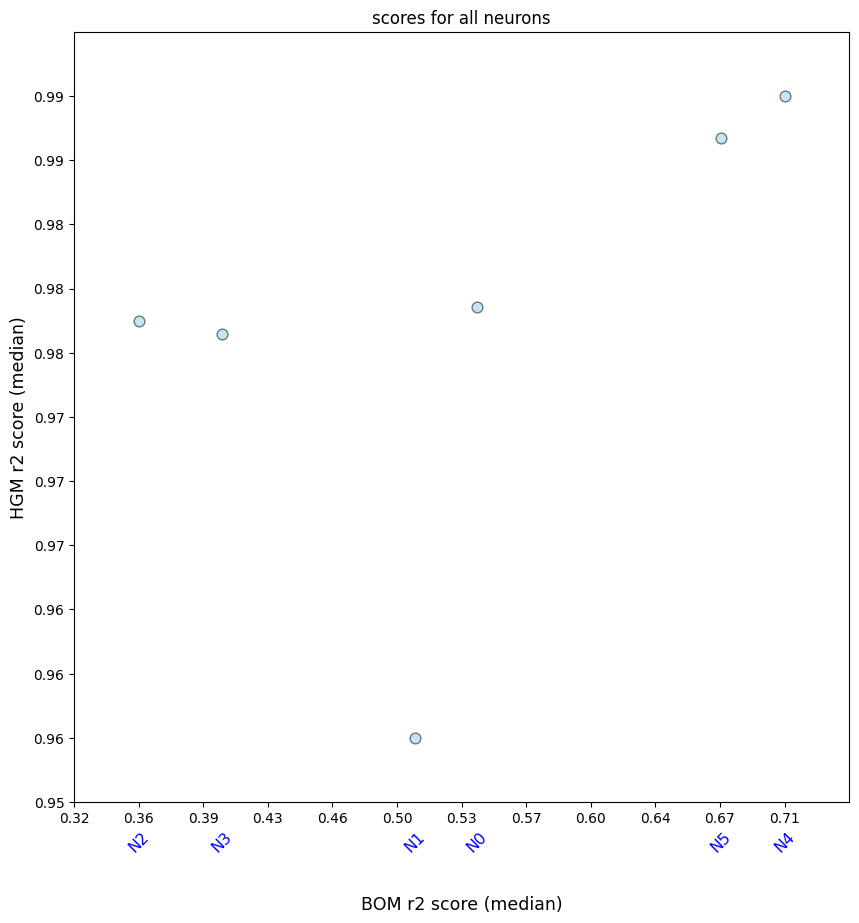

In [9]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None, force_medians=False
)

In [10]:
# plot_utils.plot_improvement_plot(
# 	neuron_scores, None,
# 	title='improvements for all neurons', limits=(-0.02, 0.02, -0.02, 0.02), force_medians=False,
# )

In [11]:
max_neurons = 10

relevant_hgm_n = list(reversed(sorted({key: value for key, value in neuron_scores.items() if 0 < value[0] < value[1]}.items(), key=lambda x: np.median(x[1][1]))))[:max_neurons]
relevant_hgm_n_labels = list([val[0] for val in relevant_hgm_n])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in relevant_hgm_n]))

NEURON: N4,		HGMSCR: 0.9906
NEURON: N5,		HGMSCR: 0.9883
NEURON: N0,		HGMSCR: 0.9789
NEURON: N2,		HGMSCR: 0.9781
NEURON: N3,		HGMSCR: 0.9775
NEURON: N1,		HGMSCR: 0.9552


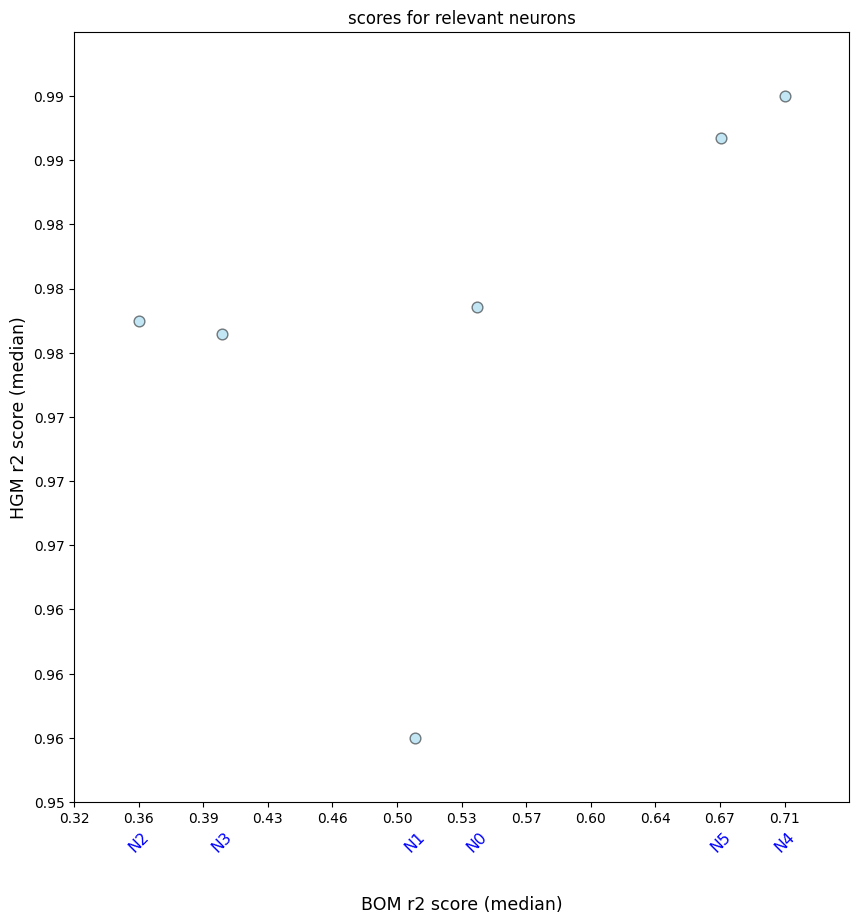

In [12]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n_labels}, None,
	title='scores for relevant neurons', limits=None, force_medians=False
)

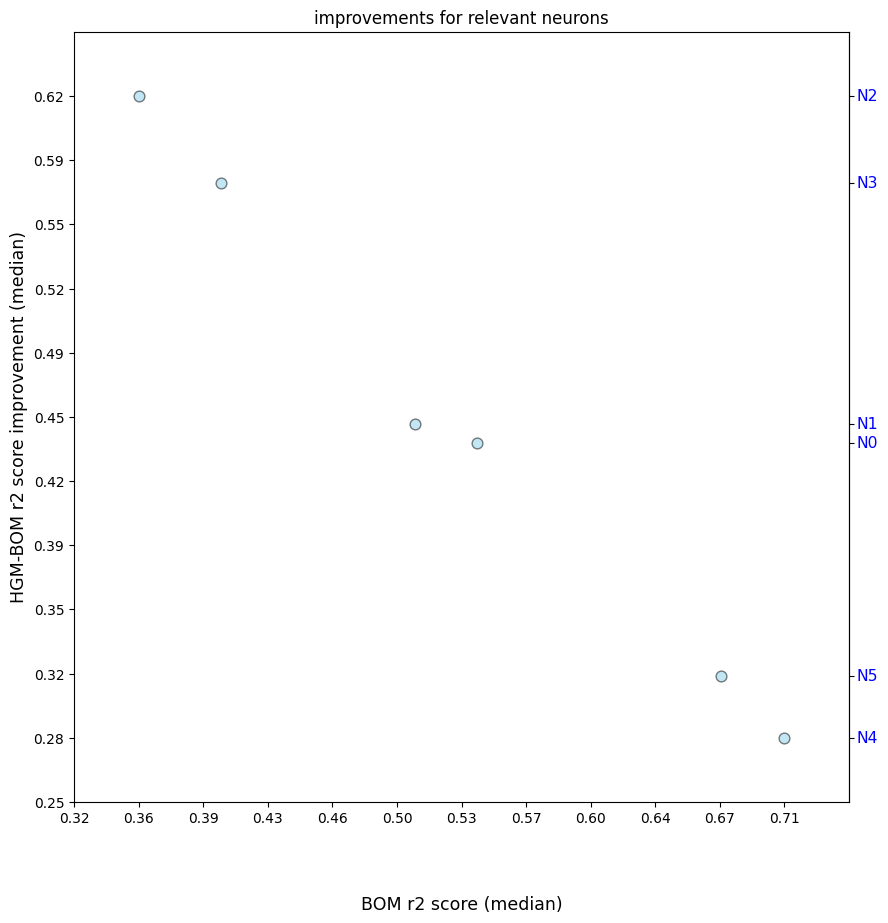

In [13]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n_labels}, None,
	title='improvements for relevant neurons', limits=None, force_medians=False
)

In [14]:
relevant_hgm_n_impr = list(reversed(sorted(relevant_hgm_n, key=lambda x: np.median(x[1][1] - x[1][0]))))
relevant_hgm_n_impr_labels = list([val[0] for val in relevant_hgm_n_impr])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in relevant_hgm_n_impr]))

NEURON: N2,		IMPR: 0.6229
NEURON: N3,		IMPR: 0.5771
NEURON: N1,		IMPR: 0.4491
NEURON: N0,		IMPR: 0.4394
NEURON: N5,		IMPR: 0.3156
NEURON: N4,		IMPR: 0.2831
